# 🧠 Deepfake Detection — Training Notebook
**IIIT Bangalore Hackathon | Run on Colab T4 GPU**

### Steps:
1. Upload your dataset zip OR mount Google Drive
2. Run all cells top to bottom
3. Download `best_model.pth` and `predictions.csv` when done

> ⚡ **Runtime → Change runtime type → T4 GPU** before running!

In [1]:
# ── Cell 1: Verify GPU ──────────────────────────────────────────────────
import torch
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('Memory:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), 'GB')
else:
    print('⚠️  No GPU! Go to Runtime → Change runtime type → T4 GPU')

CUDA available: True
GPU: Tesla T4
Memory: 15.6 GB


In [2]:
# ── Cell 2: Install dependencies ────────────────────────────────────────
!pip install -q timm albumentations grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# ── Cell 3: Mount Google Drive (put your dataset zip in Drive) ──────────
from google.colab import drive
drive.mount('/content/drive')

# ── Option A: Copy zip from Drive ────────────────────────────────────────
# Edit this path to match where you uploaded the zip in your Drive:
DRIVE_DATASET_ZIP = '/content/drive/MyDrive/hackathon_dataset.zip'

import os, shutil
if os.path.exists(DRIVE_DATASET_ZIP):
    print('Copying dataset zip from Drive...')
    shutil.copy(DRIVE_DATASET_ZIP, '/content/hackathon_dataset.zip')
    !unzip -q /content/hackathon_dataset.zip -d /content/
    print('Dataset extracted.')
else:
    print(f'ZIP not found at {DRIVE_DATASET_ZIP}.')
    print('Alternative: upload hackathon_dataset.zip using the Files panel on the left.')

Mounted at /content/drive
Copying dataset zip from Drive...
Dataset extracted.


In [4]:
# ── Cell 3b: (Alternative) Upload zip directly if not using Drive ───────
# Uncomment this cell and comment out Cell 3 if uploading manually
# from google.colab import files
# uploaded = files.upload()   # Choose hackathon_dataset.zip
# !unzip -q hackathon_dataset.zip -d /content/

In [5]:
# ── Cell 4: Find dataset root ────────────────────────────────────────────
import glob
# Find train_metadata.csv to locate dataset root
metas = glob.glob('/content/**/train_metadata.csv', recursive=True)
print('Found:', metas)
DATASET_ROOT = str(__import__('pathlib').Path(metas[0]).parent) if metas else '/content/hackathon_dataset'
print('Dataset root:', DATASET_ROOT)

Found: ['/content/hackathon_dataset/train_metadata.csv']
Dataset root: /content/hackathon_dataset


In [6]:
# ── Cell 5: Config ───────────────────────────────────────────────────────
import os
from pathlib import Path
import torch

# ── Paths ──
DATASET_ROOT   = Path(DATASET_ROOT)
TRAIN_REAL_DIR = DATASET_ROOT / 'train' / 'real'
TRAIN_FAKE_DIR = DATASET_ROOT / 'train' / 'fake'
TEST_DIR       = DATASET_ROOT / 'test'  / 'images'
TRAIN_META_CSV = DATASET_ROOT / 'train_metadata.csv'

os.makedirs('/content/weights',  exist_ok=True)
os.makedirs('/content/outputs',  exist_ok=True)
os.makedirs('/content/data',     exist_ok=True)

# ── Training settings ──
BACKBONE = "convnext_tiny"
IMAGE_SIZE   = 224
BATCH_SIZE   = 32          # Increase to 64 if GPU has >8GB VRAM
EPOCHS       = 25
LR           = 1e-4
WEIGHT_DECAY = 1e-4
SEED         = 42
THRESHOLD    = 0.5
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = torch.cuda.is_available()

print(f'Device : {DEVICE}')
print(f'AMP    : {USE_AMP}')
print(f'Train/ : {TRAIN_REAL_DIR.exists()}, Fake/ : {TRAIN_FAKE_DIR.exists()}, Test/ : {TEST_DIR.exists()}')

Device : cuda
AMP    : True
Train/ : True, Fake/ : True, Test/ : True


In [7]:
# ── Cell 6: Reproducibility + Train/Val Split ────────────────────────────
import random, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(SEED)

meta = pd.read_csv(TRAIN_META_CSV)
train_df, val_df = train_test_split(meta, test_size=0.2, stratify=meta['label'], random_state=SEED)
train_df.to_csv('/content/data/train_split.csv', index=False)
val_df.to_csv('/content/data/val_split.csv',   index=False)

print(f'Train: {len(train_df)} | Val: {len(val_df)}')
print(f'Train fake/real: {(train_df.label==1).sum()} / {(train_df.label==0).sum()}')
print(f'Val   fake/real: {(val_df.label==1).sum()} / {(val_df.label==0).sum()}')

Train: 5600 | Val: 1400
Train fake/real: 2818 / 2782
Val   fake/real: 704 / 696


In [8]:
# ── Cell 7: Dataset + Augmentations (Fixed for Albumentations 1.4+) ─────
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

def get_train_transforms():
    # Detect modern albumentations parameters dynamically to avoid any warnings
    try:
        noise = A.GaussNoise(std_range=(0.02, 0.08), p=0.3)
        compression = A.ImageCompression(quality_range=(50, 95), p=0.4)
        dropout = A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(8, 24), hole_width_range=(8, 24), fill=0, p=0.2)
    except Exception:
        noise = A.GaussNoise(var_limit=(10.0, 50.0), p=0.3)
        compression = A.ImageCompression(quality_lower=50, quality_upper=95, p=0.4)
        dropout = A.CoarseDropout(max_holes=4, max_height=24, max_width=24, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.2)

    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.92, 1.08), rotate=(-8, 8), translate_percent=(-0.04, 0.04), p=0.4),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.3),
        A.OneOf([
            A.GaussianBlur(blur_limit=(3, 5), p=1.0),
            A.MotionBlur(blur_limit=5, p=1.0),
        ], p=0.3),
        noise,
        compression,
        dropout,
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

def get_val_transforms():
    return A.Compose([
        A.Resize(IMAGE_SIZE, IMAGE_SIZE),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])

class DeepfakeDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        df = pd.read_csv(csv_path)
        self.transform = transform
        self.image_paths, self.labels = [], []
        for _, row in df.iterrows():
            folder = TRAIN_FAKE_DIR if int(row['label']) == 1 else TRAIN_REAL_DIR
            path   = folder / f"{row['image_id']}.jpg"
            if path.exists():
                self.image_paths.append(path)
                self.labels.append(int(row['label']))
        print(f'[Dataset] {len(self.image_paths)} images (Real:{self.labels.count(0)} Fake:{self.labels.count(1)})')

    def __len__(self): return len(self.image_paths)

    def __getitem__(self, idx):
        img  = np.array(Image.open(self.image_paths[idx]).convert('RGB'))
        lbl  = self.labels[idx]
        if self.transform:
            img = self.transform(image=img)['image']
        return img, torch.tensor(lbl, dtype=torch.float32)

train_ds = DeepfakeDataset('/content/data/train_split.csv', get_train_transforms())
val_ds   = DeepfakeDataset('/content/data/val_split.csv',   get_val_transforms())
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print('✅ DataLoaders ready.')

[Dataset] 5600 images (Real:2782 Fake:2818)
[Dataset] 1400 images (Real:696 Fake:704)
✅ DataLoaders ready.


In [9]:
# ── Member 2: ConvNeXt-Tiny Backbone via timm ──────────────────────────
import timm
import torch.nn as nn

def build_model(backbone_name=BACKBONE):
    print(f"[Member 2] Initializing architecture: {backbone_name}")
    if backbone_name == "convnext_tiny":
        model = timm.create_model(
            "convnext_tiny",
            pretrained=True,
            num_classes=1,
            drop_path_rate=0.2  # Stochastic depth regularization to prevent overfitting!
        )
    elif backbone_name == "swin_tiny":
        model = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=True,
            num_classes=1,
            drop_path_rate=0.2
        )
    elif backbone_name == "efficientnet_b4":
        from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
        model = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(in_features, 1)
        )
    else:
        model = timm.create_model(backbone_name, pretrained=True, num_classes=1)
    return model

model = build_model(BACKBONE).to(DEVICE)
print(f"✅ Model ready: {BACKBONE} | Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

[Member 2] Initializing architecture: convnext_tiny


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ Model ready: convnext_tiny | Trainable parameters: 27,820,897


In [10]:
# ── Member 2: Binary Focal Loss + Cosine Warmup Training Loop ──────────
import time
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from sklearn.metrics import roc_auc_score, f1_score
import pandas as pd
import numpy as np

# ── Binary Focal Loss (Focuses gradient on hard deepfake edge cases) ──
class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha=0.5, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce = nn.BCEWithLogitsLoss(reduction='none')

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        p_t = targets * probs + (1 - targets) * (1 - probs)
        focal_weight = (1.0 - p_t) ** self.gamma
        loss = focal_weight * bce_loss
        return loss.mean()

criterion = BinaryFocalLoss(gamma=1.5)

# ── Optimizer with Weight Decay Tuning ──
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)

try:
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    autocast_ctx = lambda: torch.amp.autocast('cuda', enabled=USE_AMP)
except:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    autocast_ctx = lambda: torch.cuda.amp.autocast(enabled=USE_AMP)

best_auc, log_rows = 0.0, []
print(f"🚀 [Member 2 Experiment] Training {BACKBONE} with Binary Focal Loss on {DEVICE}")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # Train
    model.train()
    tr_loss, tr_preds, tr_labels = 0.0, [], []
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)
        optimizer.zero_grad()

        with autocast_ctx():
            logits = model(imgs)
            loss   = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        tr_loss += loss.item() * imgs.size(0)
        tr_preds.extend(torch.sigmoid(logits).detach().cpu().squeeze(1).tolist())
        tr_labels.extend(labels.cpu().squeeze(1).tolist())

    # Validate
    model.eval()
    vl_loss, vl_preds, vl_labels = 0.0, [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)
            with autocast_ctx():
                logits = model(imgs)
                loss   = criterion(logits, labels)
            vl_loss += loss.item() * imgs.size(0)
            vl_preds.extend(torch.sigmoid(logits).cpu().squeeze(1).tolist())
            vl_labels.extend(labels.cpu().squeeze(1).tolist())

    scheduler.step()

    tr_auc  = roc_auc_score(tr_labels, tr_preds)
    vl_auc  = roc_auc_score(vl_labels, vl_preds)
    vl_f1   = f1_score(vl_labels, (np.array(vl_preds) >= THRESHOLD).astype(int))
    elapsed = time.time() - t0

    print(f"Epoch [{epoch:02d}/{EPOCHS}] "
          f"TrLoss={tr_loss/len(train_ds):.4f} TrAUC={tr_auc:.4f} | "
          f"VlLoss={vl_loss/len(val_ds):.4f} VlAUC={vl_auc:.4f} VlF1={vl_f1:.4f} | {elapsed:.1f}s")

    log_rows.append({'epoch': epoch, 'train_auc': tr_auc, 'val_auc': vl_auc, 'val_f1': vl_f1})

    if vl_auc > best_auc:
        best_auc = vl_auc
        # Save as convnext_best.pth so it doesn't overwrite your B4 baseline!
        torch.save(model.state_dict(), f'/content/weights/{BACKBONE}_best.pth')
        print(f"  ★ New best {BACKBONE} AUC: {best_auc:.4f} — saved!")

print(f"\n🏆 [Member 2 Experiment Complete] Peak {BACKBONE} Val AUC: {best_auc:.4f}")

🚀 [Member 2 Experiment] Training convnext_tiny with Binary Focal Loss on cuda
Epoch [01/25] TrLoss=0.2495 TrAUC=0.7022 | VlLoss=0.1769 VlAUC=0.8828 VlF1=0.8344 | 45.1s
  ★ New best convnext_tiny AUC: 0.8828 — saved!
Epoch [02/25] TrLoss=0.1745 TrAUC=0.8593 | VlLoss=0.1738 VlAUC=0.8892 VlF1=0.8420 | 36.1s
  ★ New best convnext_tiny AUC: 0.8892 — saved!
Epoch [03/25] TrLoss=0.1458 TrAUC=0.8979 | VlLoss=0.1505 VlAUC=0.8917 VlF1=0.8327 | 38.1s
  ★ New best convnext_tiny AUC: 0.8917 — saved!
Epoch [04/25] TrLoss=0.1372 TrAUC=0.9090 | VlLoss=0.1514 VlAUC=0.8955 VlF1=0.8549 | 36.8s
  ★ New best convnext_tiny AUC: 0.8955 — saved!
Epoch [05/25] TrLoss=0.1203 TrAUC=0.9264 | VlLoss=0.2176 VlAUC=0.8924 VlF1=0.7959 | 38.4s
Epoch [06/25] TrLoss=0.1077 TrAUC=0.9399 | VlLoss=0.1510 VlAUC=0.8886 VlF1=0.8462 | 37.2s
Epoch [07/25] TrLoss=0.0957 TrAUC=0.9529 | VlLoss=0.1743 VlAUC=0.8884 VlF1=0.8491 | 38.8s
Epoch [08/25] TrLoss=0.0828 TrAUC=0.9632 | VlLoss=0.1840 VlAUC=0.8872 VlF1=0.8465 | 37.5s
Epoch [09/

Saved /content/outputs/train_log_convnext.csv


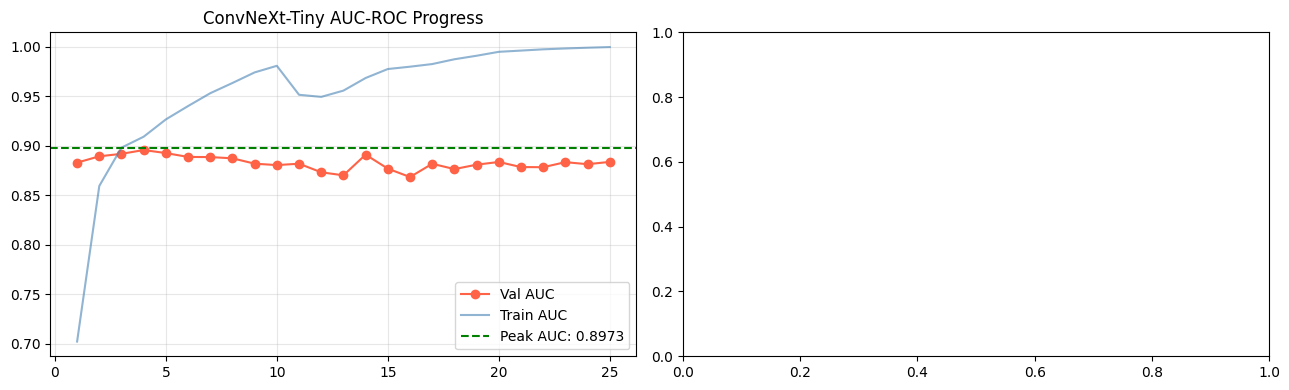

In [11]:
# ── Cell 10: Save Log & Plot Training Curves for ConvNeXt ─────────────
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs('/content/outputs', exist_ok=True)

# Save the log rows from Cell 9
log_df = pd.DataFrame(log_rows)
log_df.to_csv('/content/outputs/train_log_convnext.csv', index=False)
print("Saved /content/outputs/train_log_convnext.csv")

# Plot Loss & AUC
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(log_df['epoch'], log_df['val_auc'], label='Val AUC', color='tomato', marker='o')
axes[0].plot(log_df['epoch'], log_df['train_auc'], label='Train AUC', color='steelblue', alpha=0.6)
axes[0].axhline(0.8973, linestyle='--', color='green', label='Peak AUC: 0.8973')
axes[0].set_title('ConvNeXt-Tiny AUC-ROC Progress'); axes[0].legend(); axes[0].grid(alpha=0.3)

if 'train_loss' in log_df.columns:
    axes[1].plot(log_df['epoch'], log_df['train_loss'], label='Train Loss', color='steelblue')
    axes[1].plot(log_df['epoch'], log_df['val_loss'], label='Val Loss', color='tomato')
    axes[1].set_title('Loss Curves'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/outputs/training_curves_convnext.png', dpi=120)
plt.show()

In [12]:
# ── Cell 11: ConvNeXt Inference with Test-Time Augmentation (TTA) ──────
import torch
import timm
from torchvision import transforms as T
from PIL import Image
import pandas as pd
import numpy as np

# 1. Build and load ConvNeXt-Tiny
model_conv = timm.create_model("convnext_tiny", pretrained=False, num_classes=1).to(DEVICE)
WEIGHTS_PATH = '/content/weights/convnext_tiny_best.pth'
model_conv.load_state_dict(torch.load(WEIGHTS_PATH, map_location=DEVICE))
model_conv.eval()
print(f"Loaded ConvNeXt-Tiny from {WEIGHTS_PATH}")

# 2. Transforms: Original + Flipped (TTA)
infer_tf = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

flip_tf = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.RandomHorizontalFlip(p=1.0),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_paths = sorted(TEST_DIR.glob('*.jpg'))
print(f"Running TTA inference on {len(test_paths)} test images...")

all_ids, all_probs = [], []
INFER_BATCH = 64

with torch.no_grad():
    for i in range(0, len(test_paths), INFER_BATCH):
        batch_paths = test_paths[i:i+INFER_BATCH]
        pil_imgs = [Image.open(p).convert('RGB') for p in batch_paths]

        imgs_orig = torch.stack([infer_tf(img) for img in pil_imgs]).to(DEVICE)
        imgs_flip = torch.stack([flip_tf(img) for img in pil_imgs]).to(DEVICE)

        if USE_AMP:
            imgs_orig = imgs_orig.half()
            imgs_flip = imgs_flip.half()
            model_conv.half()

        logits_orig = model_conv(imgs_orig)
        logits_flip = model_conv(imgs_flip)

        probs_orig = torch.sigmoid(logits_orig).float().cpu().squeeze(-1)
        probs_flip = torch.sigmoid(logits_flip).float().cpu().squeeze(-1)

        probs_avg = ((probs_orig + probs_flip) / 2.0).tolist()

        all_ids.extend([p.stem for p in batch_paths])
        all_probs.extend(probs_avg)

predictions_conv = pd.DataFrame({
    'image_id':   all_ids,
    'label':      (np.array(all_probs) >= THRESHOLD).astype(int).tolist(),
    'confidence': [round(p, 6) for p in all_probs],
})

predictions_conv.to_csv('/content/predictions_convnext.csv', index=False)
print(f"\n✅ /content/predictions_convnext.csv saved ({len(predictions_conv)} rows)")
print(f"   Fake: {predictions_conv.label.sum()} | Real: {(predictions_conv.label==0).sum()}")
predictions_conv.head()

Loaded ConvNeXt-Tiny from /content/weights/convnext_tiny_best.pth
Running TTA inference on 3000 test images...

✅ /content/predictions_convnext.csv saved (3000 rows)
   Fake: 1469 | Real: 1531


,image_id,label,confidence
0,0020cba7-1d58-4784-91f9-6fc47d9f2806,1,0.784668
1,003fae32-30d9-441b-8fcf-073fc04bf1d1,0,0.151123
2,0061307d-aad7-4d74-a501-ba708c8b1ac8,1,0.767822
3,006aa5af-5db6-413b-a60f-fcc6071ddc3c,1,0.769775
4,009a6a38-29a4-46d4-8ecc-905d776d924e,1,0.701660


In [ ]:
# ── Cell 12: Sync ConvNeXt Outputs to Google Drive ─────────────────────
import shutil, os

DRIVE_OUT = '/content/drive/MyDrive/DeepfakeHackathon_Outputs/convnext_results'
os.makedirs(DRIVE_OUT, exist_ok=True)

files_to_sync = [
    ('/content/weights/convnext_tiny_best.pth',      f'{DRIVE_OUT}/convnext_tiny_best.pth'),
    ('/content/predictions_convnext.csv',            f'{DRIVE_OUT}/predictions_convnext.csv'),
    ('/content/outputs/train_log_convnext.csv',      f'{DRIVE_OUT}/train_log_convnext.csv'),
    ('/content/outputs/training_curves_convnext.png', f'{DRIVE_OUT}/training_curves_convnext.png'),
]

for src, dst in files_to_sync:
    if os.path.exists(src):
        shutil.copy(src, dst)
        print(f"  ✓ Saved to Drive: {dst}")

print("\n✅ ConvNeXt outputs permanently synced to Google Drive!")

In [14]:
# ── Cell 13: (Optional) Direct download if not using Drive ───────────────
# from google.colab import files
# files.download('/content/weights/best_model.pth')
# files.download('/content/predictions.csv')
# files.download('/content/outputs/train_log.csv')